# Laboratorio 2 — Exploración de Datos (EDA) e Hipótesis de Asociación
**Especialización en Analítica Estratégica de Datos · Estadística para Analítica de Datos · UPTC**
Profesor: Duván Cataño

**Equipo:** Edwart Stevens González Ríos · Karen Julieth Hernández Chaparro · Deisy Carolina Monroy Gutiérrez

**Base de datos:** Encuesta de afectación digital de entidades públicas por el terremoto del 10 de agosto de 2026 (MinTIC), cruzada con el
índice de pobreza multidimensional municipal del DANE (2018).

Contenido: L2-1 contexto y definición poblacional · L2-2 medidas descriptivas · L2-3 forma y atípicos · L2-4 correlación · L2-5 independencia
(χ² e información mutua) · L2-6 ANOVA frente a Kruskal-Wallis · L2-7 síntesis. Todos los resultados numéricos se redondean a
**cuatro cifras decimales**. Los resultados alimentan la aplicación de Streamlit (`app/app.py`).

### Instalación de librerías
Ejecute esta celda primero. Revisa qué librerías faltan en el Python que usa el notebook (Colab, VS Code o Jupyter) y las instala.
Si al final pide reiniciar, use **Restart** en el kernel y vuelva a ejecutar todo desde el inicio.

In [1]:
import sys, subprocess, importlib, importlib.util
REQUERIDAS = {'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib', 'seaborn': 'seaborn',
              'scipy': 'scipy', 'openpyxl': 'openpyxl', 'sklearn': 'scikit-learn'}   # módulo -> paquete de pip
faltantes = [pip for mod, pip in REQUERIDAS.items() if importlib.util.find_spec(mod) is None]
if faltantes:
    print('Instalando:', ', '.join(faltantes))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *faltantes])
    importlib.invalidate_caches()
    print('Instalación terminada.')
else:
    print('Todas las librerías están instaladas.')
print('Python en uso:', sys.executable)
aun_faltan = [m for m in REQUERIDAS if importlib.util.find_spec(m) is None]
if aun_faltan:
    print('ATENCIÓN: siguen faltando', aun_faltan, '-> reinicie el kernel (Restart) y ejecute de nuevo esta celda.')

Todas las librerías están instaladas.
Python en uso: /usr/bin/python3


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
import warnings, os
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 80)
pd.set_option('display.max_colwidth', 70)
pd.set_option('display.width', 200)

# Paleta (azul de referencia + rampa secuencial para la variable objetivo ordinal)
AZUL = '#2a78d6'; GRIS = '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'axes.axisbelow': True,
                     'axes.titleweight': 'bold', 'axes.titlesize': 11, 'font.size': 9})

### Carga de los insumos del Laboratorio 1
El Laboratorio 2 **no repite** la limpieza: lee las bases que exporta el notebook `01_Lab1_EDA_Encuesta_Terremoto.ipynb` en `data/processed/`.
Si esos archivos no existen, ejecute primero el notebook del Lab 1 (*Run All*).

| Objeto | Archivo | Contenido |
|---|---|---|
| `df_raw` | `data/raw/Resultados_encuesta_entidades_Terremoto_20261022.csv` | Encuesta original de MinTIC (409 × 61) |
| `df` | `data/processed/base_lab1_preparada.csv` | Base depurada del Lab 1, nombres cortos y variables derivadas (409 entidades) |
| `d` | `data/processed/base_lab1_con_ipm.csv` | Entidades con IPM del DANE e índice de vulnerabilidad (408 entidades) |
| `diccionario` | `data/processed/diccionario_variables.csv` | Diccionario de variables del Lab 1 |

In [3]:
from pathlib import Path
# Raíz del proyecto = la primera carpeta (actual o superior) que contiene data/
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data').is_dir()), Path.cwd())
RAW, PROC = RAIZ / 'data' / 'raw', RAIZ / 'data' / 'processed'
PROC.mkdir(parents=True, exist_ok=True)
def ruta(nombre):
    # busca el archivo en data/raw, data/processed o la carpeta actual
    for c in [RAW / nombre, PROC / nombre, Path(nombre)]:
        if c.exists(): return str(c)
    return nombre

ARCHIVO = ruta('Resultados_encuesta_entidades_Terremoto_20261022.csv')
ARCHIVO_IPM = ruta('anexo-censal-pobreza-municipal-2018.xlsx')
for f in ['base_lab1_preparada.csv', 'base_lab1_con_ipm.csv', 'diccionario_variables.csv']:
    if not (PROC / f).exists():
        raise FileNotFoundError(f'Falta data/processed/{f}: ejecute primero el notebook del Laboratorio 1.')

TIPOS = {'cod_dpto': str, 'cod_mpio': str}
df_raw = pd.read_csv(ARCHIVO, encoding='utf-8')
df = pd.read_csv(PROC / 'base_lab1_preparada.csv', dtype=TIPOS)
d = pd.read_csv(PROC / 'base_lab1_con_ipm.csv', dtype=TIPOS)
diccionario = pd.read_csv(PROC / 'diccionario_variables.csv')

# Órdenes de las categorías (los CSV no guardan el orden) y paleta del Lab 1
ORD_OBJ = ['Sin afectación TIC', 'Bajo', 'Moderado', 'Alto', 'Crítico']
ORD_CONEC = ['Normal.', 'Degradada o inestable.', 'Disponible únicamente mediante mecanismos alternativos.', 'Sin conectividad.']
ORD_ENER = ['Sí, normal.', 'Sí, pero intermitente.', 'No.']
SEQ = ['#9ec5f4', '#6da7ec', '#3987e5', '#1c5cab', '#0d366b']
for base in (df, d):
    base['nivel_afectacion_cat'] = pd.Categorical(base['nivel_afectacion_cat'], categories=ORD_OBJ, ordered=True)

def barras(s, titulo, orden=None, ax=None, color=AZUL):
    vc = s.value_counts()
    if orden is not None: vc = vc.reindex([o for o in orden if o in vc.index])
    vc = vc.iloc[::-1]
    ax = ax or plt.subplots(figsize=(7, .45*len(vc)+1))[1]
    ax.barh([str(i).rstrip('.') for i in vc.index], vc.values, color=color, height=.65)
    tot = s.notna().sum()
    for y, v in enumerate(vc.values):
        ax.text(v + tot*.005, y, f'{v} ({v/tot:.0%})', va='center', fontsize=8, color=GRIS)
    ax.set_xlim(0, vc.max()*1.2); ax.set_title(titulo, loc='left'); ax.grid(axis='y', visible=False)
    return ax

# Asociación de las variables cualitativas con el objetivo (V de Cramér corregida, como en el Lab 1, numeral 7)
def cramers_v(x, y):
    t = pd.crosstab(x, y)
    chi2, p, dof, _ = chi2_contingency(t)
    n = t.values.sum(); r, k = t.shape
    phi2 = max(0, chi2/n - (k-1)*(r-1)/(n-1)); rc = r-(r-1)**2/(n-1); kc = k-(k-1)**2/(n-1)
    return np.sqrt(phi2 / max(1e-9, min(kc-1, rc-1))), p
EST = [c for c in df.columns if c.startswith('est_')]
candidatas = ['departamento','tipo_entidad','riesgo_continuidad','estado_sistemas','energia_estable','estado_conectividad','zonas_incomunicadas',
              *EST,'sede_contingencia','estado_infra','danos_estructurales','poliza_seguro','perdida_info','backups','contingencia','control_cuentas',
              'proveedores_sla','requiere_colcert','personal_afectado','personal_suficiente','tramites_impedidos','digitalizar','intercambio_afectado']
assoc = pd.DataFrame([dict(zip(['variable','V_de_Cramer','p_valor'], [c, *cramers_v(df[c].fillna('NA'), df['nivel_afectacion_cat'])])) for c in candidatas])
assoc = assoc.sort_values('V_de_Cramer', ascending=False).reset_index(drop=True)

print('df_raw', df_raw.shape, '| df', df.shape, '| d', d.shape, '| diccionario', diccionario.shape)

df_raw (409, 61) | df (409, 74) | d (408, 82) | diccionario (61, 7)


In [4]:
from scipy import stats
from sklearn.metrics import mutual_info_score, normalized_mutual_info_score
pd.set_option('display.float_format', lambda v: f'{v:.4f}')
R = lambda v: round(float(v), 4)   # redondeo a 4 decimales

# Base de trabajo del Lab 2 (408 entidades con IPM) y nombres legibles
lab2 = d.copy()
lab2['alto_critico'] = lab2['nivel_afectacion_cat'].isin(['Alto', 'Crítico']).astype(int)
lab2['sin_conectividad'] = (lab2['estado_conectividad'] == 'Sin conectividad.').astype(int)
ETQ_NUM = {'ipm': 'IPM municipal (%)', 'duracion_min': 'Duración del formulario (min)',
           'n_infra_afectada': 'N° de elementos de infraestructura afectados', 'indice_vulnerabilidad': 'Índice de vulnerabilidad digital (0-5)'}
print('Entidades en la base del Lab 2:', len(lab2))

Entidades en la base del Lab 2: 408


## L2-1. Contextualización del conjunto de datos y definición poblacional

| Elemento | Definición |
|---|---|
| **Población objetivo** | Entidades públicas (alcaldías, gobernaciones, ESE, instituciones educativas, institutos descentralizados y otras) de los departamentos afectados por el sismo del 10 de agosto de 2026: Risaralda, Valle del Cauca, Caldas, Chocó y Quindío |
| **Muestra en estudio** | Las 409 entidades que diligenciaron la encuesta de MinTIC entre el 20 de agosto y el 3 de septiembre de 2026 (408 con IPM del DANE). Es una **muestra no probabilística por autoselección**: responde quien quiso o pudo, por lo que puede haber sesgo de respuesta (por ejemplo, el Chocó aporta solo el 10 %) |
| **Unidad de observación** | Una entidad pública (una fila de la base) |
| **Naturaleza analítica** | **Clasificación** |
| **Variable respuesta** | Nivel general de afectación de las capacidades digitales: cualitativa ordinal de 5 clases (Sin afectación TIC < Bajo < Moderado < Alto < Crítico) |
| **Objetivo del modelado posterior** | Clasificar el nivel de afectación de cada entidad a partir de su infraestructura TIC, personal técnico y pobreza del municipio, para que MinTIC priorice la atención con criterio territorial |

In [5]:
print(f'Observaciones: {df_raw.shape[0]}  |  Variables originales: {df_raw.shape[1]}  |  Variables derivadas en el EDA: 8  |  Variables del cruce DANE: 11')
tip = diccionario['Tipología'].value_counts().rename_axis('Tipología').to_frame('N° variables (originales)')
tip.loc['Total'] = tip.sum()
display(tip)
cuant = pd.DataFrame([
    ('ipm', 'Cuantitativa continua', '% de personas en pobreza multidimensional del municipio (DANE, 2018)'),
    ('ipm_cabecera / ipm_rural', 'Cuantitativa continua', 'IPM de la cabecera y de la zona rural'),
    ('duracion_min', 'Cuantitativa continua', 'Minutos para diligenciar el formulario'),
    ('dias_post_sismo', 'Cuantitativa discreta', 'Días entre el sismo y la respuesta'),
    ('n_servicios_caidos, n_sistemas_afectados, n_infra_afectada, n_tipos_conexion, n_energia_alt, n_areas_apoyo', 'Cuantitativa discreta', 'Conteos de opciones marcadas'),
    ('indice_vulnerabilidad', 'Cuantitativa discreta', 'Suma de 5 condiciones desfavorables (0 a 5)'),
], columns=['Variable', 'Tipo', 'Descripción'])
print('Variables cuantitativas disponibles (todas derivadas o del DANE):')
display(cuant)

Observaciones: 409  |  Variables originales: 61  |  Variables derivadas en el EDA: 8  |  Variables del cruce DANE: 11


,N° variables (originales)
Tipología,
Cualitativa nominal,42
Cualitativa ordinal,17
Variable temporal,2
Total,61


Variables cuantitativas disponibles (todas derivadas o del DANE):


,Variable,Tipo,Descripción
0,ipm,Cuantitativa continua,"% de personas en pobreza multidimensional del municipio (DANE, 2018)"
1,ipm_cabecera / ipm_rural,Cuantitativa continua,IPM de la cabecera y de la zona rural
2,duracion_min,Cuantitativa continua,Minutos para diligenciar el formulario
3,dias_post_sismo,Cuantitativa discreta,Días entre el sismo y la respuesta
4,"n_servicios_caidos, n_sistemas_afectados, n_infra_afectada, n_tipo...",Cuantitativa discreta,Conteos de opciones marcadas
5,indice_vulnerabilidad,Cuantitativa discreta,Suma de 5 condiciones desfavorables (0 a 5)


In [6]:
# Faltantes e inconsistencias operacionales (resumen)
falt_total = df_raw.isna().sum().sum()
print(f'Celdas faltantes: {falt_total} de {df_raw.size} ({R(falt_total / df_raw.size * 100)} %)')
print(f'Variables con faltantes: {(df_raw.isna().sum() > 0).sum()} de {df_raw.shape[1]} (casi todas preguntas abiertas condicionales)')
print(f'Respuestas "sin información" (faltante encubierto): mediana por entidad = {R(df["n_sin_info"].median())}')
print(f'Entidades sin IPM (municipio creado después del Censo 2018): {df["ipm"].isna().sum()}')
print(f'Duraciones de 0 minutos: {(df["duracion_min"] < 0.5).sum()}  |  mayores a 2 horas: {(df["duracion_min"] > 120).sum()}')
print(f'Entidades repetidas por razón social: 9  |  variables constantes o vacías: 4')

Celdas faltantes: 5232 de 24949 (20.9708 %)
Variables con faltantes: 26 de 61 (casi todas preguntas abiertas condicionales)
Respuestas "sin información" (faltante encubierto): mediana por entidad = 7.0
Entidades sin IPM (municipio creado después del Censo 2018): 1
Duraciones de 0 minutos: 2  |  mayores a 2 horas: 14
Entidades repetidas por razón social: 9  |  variables constantes o vacías: 4


La base tiene **409 observaciones y 61 variables originales**, casi todas cualitativas (42 nominales y 17 ordinales); las variables cuantitativas son
**derivadas** (duración, días, conteos, índice de vulnerabilidad) o provienen del **DANE** (IPM). Los faltantes se concentran en preguntas abiertas
condicionales (faltantes por diseño), el faltante encubierto relevante es la respuesta *"No se ha podido determinar"* y las inconsistencias
operacionales principales son las duraciones extremas del formulario y el bloque de respuestas idénticas de Risaralda (Lab 1, sección 7.3.3).

## L2-2. Exploración univariada y medidas estructurales
Se analizan cuatro variables cuantitativas clave: **IPM municipal** (continua, territorio), **duración del formulario** (continua, calidad del dato),
**número de elementos de infraestructura afectados** (discreta, daño) e **índice de vulnerabilidad digital** (discreta, fragilidad).

In [7]:
VARS = list(ETQ_NUM)
def resumen(s):
    s = s.dropna(); moda = s.mode()
    q = s.quantile([.10, .25, .50, .75, .90])
    return pd.Series({
        'n': len(s), 'Media': s.mean(), 'Mediana': s.median(), 'Moda': moda.iloc[0] if len(moda) else np.nan,
        'Mínimo': s.min(), 'Máximo': s.max(), 'Rango': s.max() - s.min(),
        'Varianza': s.var(ddof=1), 'Desv. estándar': s.std(ddof=1), 'CV (%)': s.std(ddof=1) / s.mean() * 100,
        'P10': q[.10], 'Q1 (P25)': q[.25], 'Q2 (P50)': q[.50], 'Q3 (P75)': q[.75], 'P90': q[.90], 'IQR': q[.75] - q[.25]})
tabla_desc = pd.DataFrame({ETQ_NUM[v]: resumen(lab2[v]) for v in VARS}).round(4)
display(tabla_desc)
print('Variable con mayor variabilidad relativa (CV):', tabla_desc.loc['CV (%)'].idxmax(), '→', R(tabla_desc.loc['CV (%)'].max()), '%')

,IPM municipal (%),Duración del formulario (min),N° de elementos de infraestructura afectados,Índice de vulnerabilidad digital (0-5)
n,408.0000,408.0000,408.0000,408.0000
Media,35.1066,53.8763,2.3431,1.9608
Mediana,33.3000,12.2667,2.0000,2.0000
Moda,35.6000,3.2833,1.0000,2.0000
Mínimo,11.5000,0.0000,0.0000,0.0000
Máximo,90.6000,5215.7167,14.0000,5.0000
Rango,79.1000,5215.7167,14.0000,5.0000
Varianza,296.4436,114463.9606,2.7223,1.1729
Desv. estándar,17.2175,338.3252,1.6499,1.0830
CV (%),49.0436,627.9662,70.4153,55.2334


Variable con mayor variabilidad relativa (CV): Duración del formulario (min) → 627.9662 %


**Interpretación** (las cifras exactas están en la tabla):

* **Tendencia central.** En el IPM y en la duración la **media supera a la mediana**, señal de asimetría positiva: unos pocos municipios muy pobres
  (Chocó) y unos pocos formularios muy largos arrastran la media hacia arriba. En la duración la diferencia es enorme (media ≈ 54 min frente a mediana
  ≈ 12 min), por lo que la mediana es la medida representativa. En el índice de vulnerabilidad media, mediana y moda casi coinciden (≈ 2): distribución
  aproximadamente simétrica.
* **Dispersión.** La **duración del formulario** tiene, por mucho, la mayor variabilidad relativa (CV > 600 %), producto de valores extremos (hasta
  ≈ 5.216 min, varios días con el formulario abierto). El IPM tiene un CV cercano al 50 %, reflejo de la gran diferencia entre el Chocó y el Eje
  Cafetero.
* **Posición.** El 50 % central de las entidades está en municipios con IPM entre Q1 y Q3 (≈ 22 % y 40 %), pero el P90 (≈ 63 %) muestra la cola de
  municipios muy pobres. En infraestructura afectada, el 90 % de las entidades reporta 4 elementos o menos.

## L2-3. Medidas de forma y representaciones gráficas univariadas

In [8]:
def clasif_asim(g):
    return 'Aprox. simétrica' if abs(g) < 0.5 else ('Asimétrica positiva' if g > 0 else 'Asimétrica negativa')
def clasif_curt(e):
    return 'Mesocúrtica' if abs(e) < 0.5 else ('Leptocúrtica' if e > 0 else 'Platicúrtica')
forma = []
for v in VARS:
    s = lab2[v].dropna()
    g1 = stats.skew(s, bias=False); k = stats.kurtosis(s, fisher=False, bias=False); ek = k - 3
    forma.append({'Variable': ETQ_NUM[v], 'Asimetría (g1)': R(g1), 'Curtosis': R(k), 'Exceso de curtosis': R(ek),
                  'Forma': clasif_asim(g1), 'Apuntamiento': clasif_curt(ek)})
forma = pd.DataFrame(forma).set_index('Variable'); display(forma)

,Asimetría (g1),Curtosis,Exceso de curtosis,Forma,Apuntamiento
Variable,,,,,
IPM municipal (%),1.0788,3.5263,0.5263,Asimétrica positiva,Leptocúrtica
Duración del formulario (min),12.8247,179.6626,176.6626,Asimétrica positiva,Leptocúrtica
N° de elementos de infraestructura afectados,2.4886,13.0551,10.0551,Asimétrica positiva,Leptocúrtica
Índice de vulnerabilidad digital (0-5),0.2647,3.2674,0.2674,Aprox. simétrica,Mesocúrtica


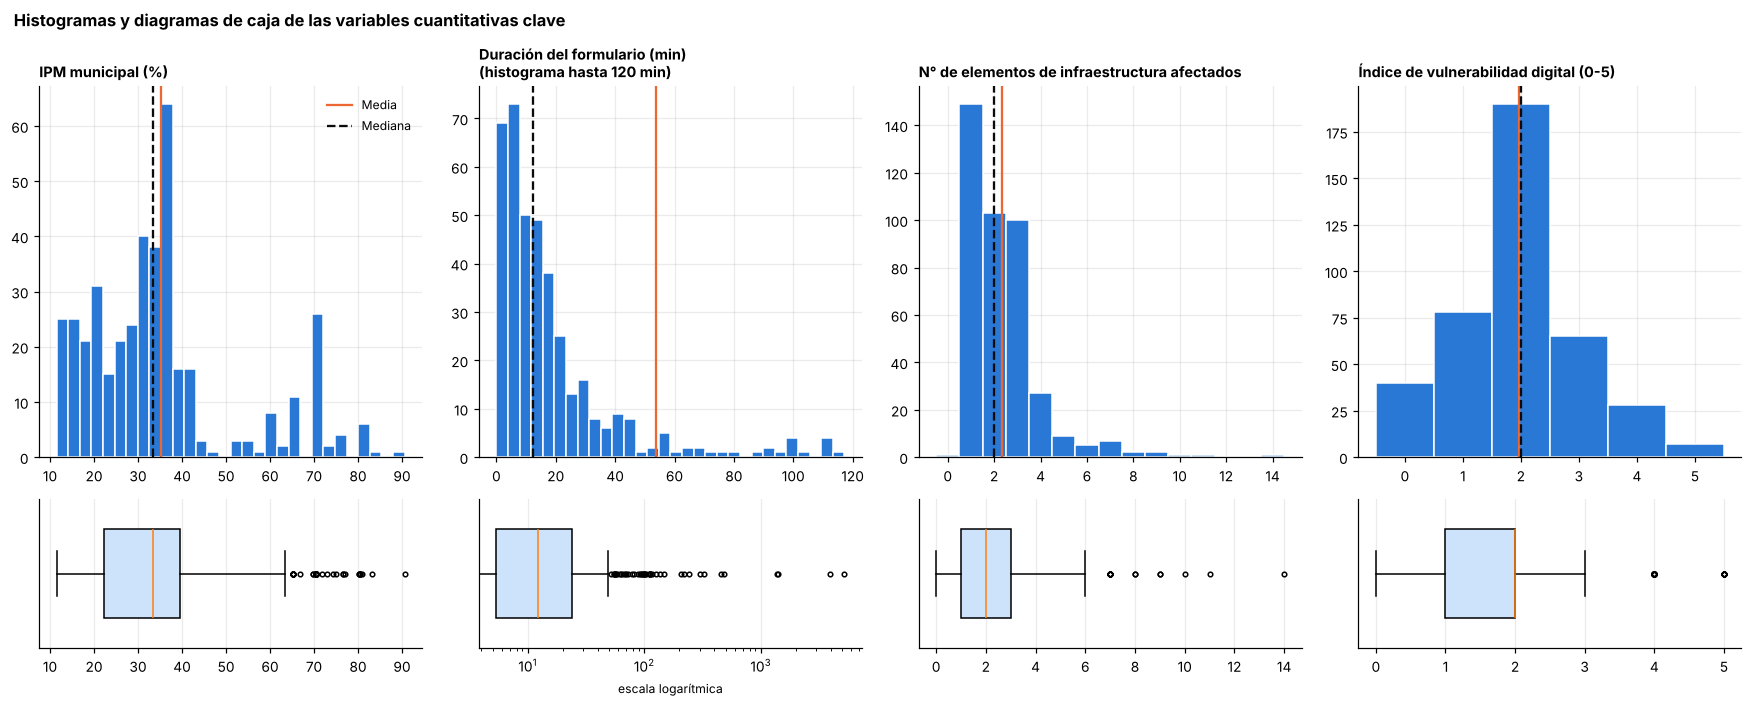

In [9]:
fig, axs = plt.subplots(2, 4, figsize=(16, 6.5), gridspec_kw={'height_ratios': [3, 1.2]})
for j, v in enumerate(VARS):
    s = lab2[v].dropna()
    if v == 'duracion_min':
        axs[0, j].hist(s[s <= 120], bins=30, color=AZUL, edgecolor='white'); axs[0, j].set_title(ETQ_NUM[v] + '\n(histograma hasta 120 min)', loc='left', fontsize=9.5)
    else:
        bins = np.arange(s.min(), s.max() + 2) - 0.5 if v in ('n_infra_afectada', 'indice_vulnerabilidad') else 30
        axs[0, j].hist(s, bins=bins, color=AZUL, edgecolor='white'); axs[0, j].set_title(ETQ_NUM[v], loc='left', fontsize=9.5)
    axs[0, j].axvline(s.mean(), color='#eb6834', lw=1.5, label='Media'); axs[0, j].axvline(s.median(), color='#0b0b0b', lw=1.5, ls='--', label='Mediana')
    axs[1, j].boxplot(s, vert=False, widths=.6, patch_artist=True, boxprops=dict(facecolor='#cde2fb'), flierprops=dict(markersize=3))
    axs[1, j].set_yticks([])
    if v == 'duracion_min': axs[1, j].set_xscale('log'); axs[1, j].set_xlabel('escala logarítmica', fontsize=8)
axs[0, 0].legend(frameon=False, fontsize=8)
plt.suptitle('Histogramas y diagramas de caja de las variables cuantitativas clave', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

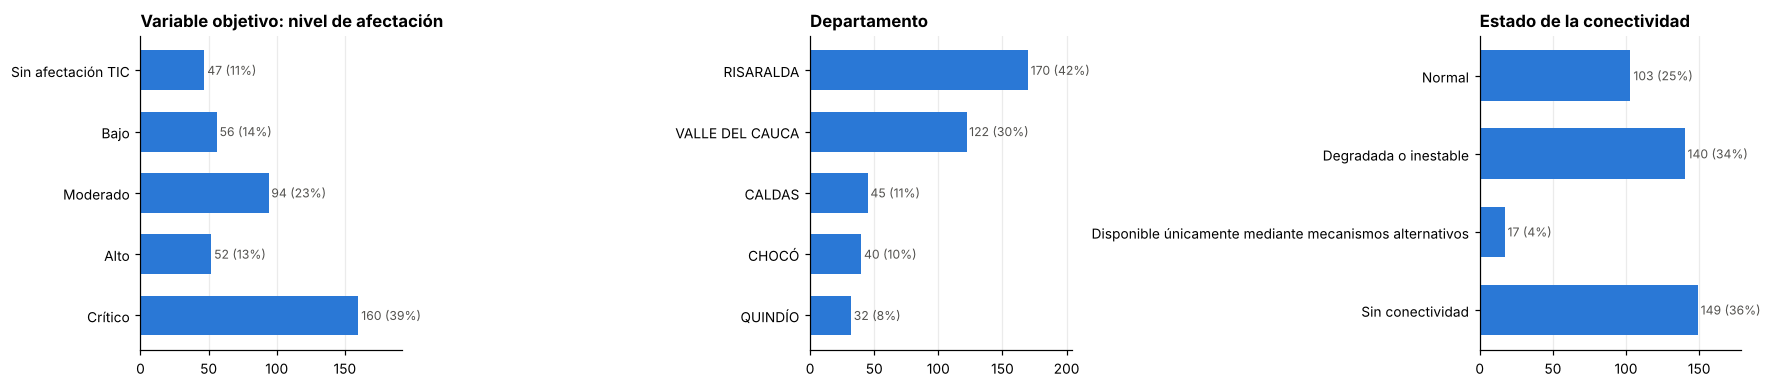

In [10]:
# Gráficos de barras de las variables cualitativas de interés
fig, axs = plt.subplots(1, 3, figsize=(16, 3.6))
barras(df['nivel_afectacion_cat'].astype(str), 'Variable objetivo: nivel de afectación', ORD_OBJ, ax=axs[0])
barras(df['departamento'], 'Departamento', ax=axs[1])
barras(df['estado_conectividad'], 'Estado de la conectividad', ORD_CONEC, ax=axs[2])
plt.tight_layout(); plt.show()

In [11]:
# Detección de atípicos con el criterio del rango intercuartílico (IQR) e impacto en las medidas descriptivas
filas = []
for v in VARS:
    s = lab2[v].dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    li, ls_ = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = (s < li) | (s > ls_); s_sin = s[~out]
    filas.append({'Variable': ETQ_NUM[v], 'Límite inferior': R(li), 'Límite superior': R(ls_), 'N° atípicos': int(out.sum()),
                  '% atípicos': R(out.mean() * 100), 'Media con atípicos': R(s.mean()), 'Media sin atípicos': R(s_sin.mean()),
                  'Mediana con atípicos': R(s.median()), 'Mediana sin atípicos': R(s_sin.median()),
                  'Desv. est. con atípicos': R(s.std()), 'Desv. est. sin atípicos': R(s_sin.std()),
                  'Cambio en la media (%)': R((s_sin.mean() - s.mean()) / s.mean() * 100)})
iqr_tab = pd.DataFrame(filas).set_index('Variable'); display(iqr_tab.T)

Variable,IPM municipal (%),Duración del formulario (min),N° de elementos de infraestructura afectados,Índice de vulnerabilidad digital (0-5)
Límite inferior,-3.3500,-22.1375,-2.0000,-0.5000
Límite superior,65.2500,51.2292,6.0000,3.5000
N° atípicos,51.0000,43.0000,14.0000,35.0000
% atípicos,12.5000,10.5392,3.4314,8.5784
Media con atípicos,35.1066,53.8763,2.3431,1.9608
Media sin atípicos,29.8655,13.7527,2.1269,1.7507
Mediana con atípicos,33.3000,12.2667,2.0000,2.0000
Mediana sin atípicos,31.6000,11.2167,2.0000,2.0000
Desv. est. con atípicos,17.2175,338.3252,1.6499,1.0830
Desv. est. sin atípicos,10.6903,10.9394,1.1455,0.8673


**Interpretación de forma y atípicos**

* **Duración del formulario:** asimetría positiva extrema y fuertemente **leptocúrtica** (exceso de curtosis muy alto). Los atípicos por IQR son los
  formularios que quedaron abiertos horas o días; al retirarlos la media cae drásticamente y la desviación estándar se reduce en más de un orden de
  magnitud, mientras la mediana casi no cambia. Es la variable donde los atípicos más distorsionan las medidas clásicas.
* **IPM municipal:** asimetría positiva moderada y ligeramente leptocúrtica; sus atípicos por IQR (51 entidades, 12,5 %) están en municipios con IPM
  superior a 65,25 %, casi todos del **Chocó**. No son errores: son la realidad territorial que motiva el enfoque del proyecto, por lo que **no se
  eliminan**. Al excluirlos la media baja ≈ 15 % y la desviación estándar cae de ≈ 17,2 a ≈ 10,7.
* **Infraestructura afectada:** asimetría positiva y leptocúrtica (pocas entidades marcan muchos elementos).
* **Índice de vulnerabilidad:** aproximadamente simétrico y mesocúrtico. El criterio IQR marca 35 entidades con índice 4 o 5, pero solo porque el IQR
  es de un punto en una escala discreta de 0 a 5; son valores posibles y relevantes (las entidades más frágiles), no atípicos que deban eliminarse.
* **Implicación:** la presencia de asimetría y atípicos hace preferibles la mediana, el IQR y las **pruebas no paramétricas** (Spearman, Kendall,
  Kruskal-Wallis) para estas variables.

## L2-4. Asociación y dependencia entre variables continuas

El IPM es una característica del **municipio**: si se correlaciona a nivel de entidad, un mismo valor se repite tantas veces como entidades respondieron
en ese municipio (pseudorreplicación). Por eso los pares territoriales se analizan **a nivel municipal (107 municipios)**, agregando la encuesta como
proporciones por municipio, y se incorporan las privaciones municipales del DANE. Se evalúan tres pares:

1. **IPM vs. % de entidades del municipio que dependen de internet satelital** (pobreza ↔ fragilidad de la conexión).
2. **IPM vs. % de hogares sin acceso a fuente de agua mejorada** (DANE): relación monótona pero no lineal.
3. **Duración del formulario vs. IPM** (nivel entidad, n = 408): par con atípicos extremos.

In [12]:
ARCHIVO_IPM_PRIV = ARCHIVO_IPM
priv = pd.read_excel(ARCHIVO_IPM_PRIV, sheet_name='6_Privaciones IPM Dpt-Mpio', header=1, dtype={'ID': str}).rename(columns={'ID': 'cod_mpio'})
mun = (lab2.groupby('cod_mpio').agg(departamento=('departamento', 'first'), n_entidades=('id', 'size'), ipm=('ipm', 'first'),
                                    pct_satelite=('depende_satelite', 'mean'), pct_sin_conectividad=('sin_conectividad', 'mean'),
                                    pct_alto_critico=('alto_critico', 'mean'), vulnerabilidad_media=('indice_vulnerabilidad', 'mean'))
       .reset_index().merge(priv[['cod_mpio', 'Sin acceso a fuente de agua mejorada', 'Trabajo informal', 'Analfabetismo']], on='cod_mpio', how='left'))
for c in ['pct_satelite', 'pct_sin_conectividad', 'pct_alto_critico']: mun[c] = mun[c] * 100
mun = mun.rename(columns={'Sin acceso a fuente de agua mejorada': 'sin_agua_mejorada'})
print('Municipios:', len(mun)); display(mun.head())

Municipios: 107


,cod_mpio,departamento,n_entidades,ipm,pct_satelite,pct_sin_conectividad,pct_alto_critico,vulnerabilidad_media,sin_agua_mejorada,Trabajo informal,Analfabetismo
0,17001,CALDAS,12,13.9000,8.3333,8.3333,25.0000,1.9167,3.6000,70.4000,5.8000
1,17013,CALDAS,2,30.0000,50.0000,0.0000,50.0000,1.0000,23.2000,86.0000,15.7000
2,17042,CALDAS,2,32.5000,0.0000,0.0000,0.0000,1.0000,21.8000,86.5000,13.0000
3,17050,CALDAS,2,32.1000,0.0000,0.0000,0.0000,1.5000,16.1000,84.9000,14.8000
4,17088,CALDAS,1,41.2000,0.0000,0.0000,0.0000,0.0000,20.1000,87.3000,20.5000


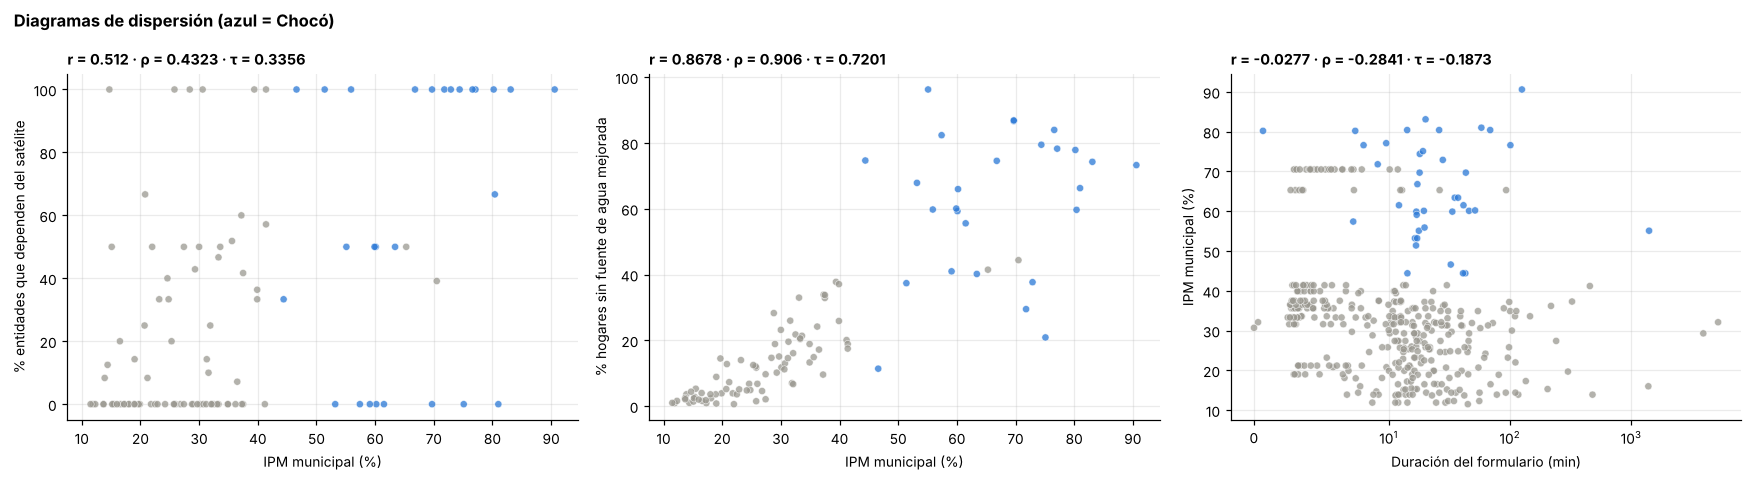

,Nivel,Covarianza,Pearson r,p Pearson,Spearman ρ,p Spearman,Kendall τ,p Kendall
Par,,,,,,,,
IPM municipal (%) vs % entidades que dependen del satélite,Municipal (n = 107),395.9057,0.5120,0.0000,0.4323,0.0000,0.3356,0.0000
IPM municipal (%) vs % hogares sin fuente de agua mejorada,Municipal (n = 107),460.6359,0.8678,0.0000,0.9060,0.0000,0.7201,0.0000
Duración del formulario (min) vs IPM municipal (%),Entidad (n = 408),-161.4720,-0.0277,0.5766,-0.2841,0.0000,-0.1873,0.0000


In [13]:
PARES = [('ipm', 'pct_satelite', mun, 'IPM municipal (%)', '% entidades que dependen del satélite', 'Municipal (n = 107)'),
         ('ipm', 'sin_agua_mejorada', mun, 'IPM municipal (%)', '% hogares sin fuente de agua mejorada', 'Municipal (n = 107)'),
         ('duracion_min', 'ipm', lab2, 'Duración del formulario (min)', 'IPM municipal (%)', 'Entidad (n = 408)')]
filas = []
fig, axs = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, (x, y, base, lx, ly, nivel) in zip(axs, PARES):
    t = base[[x, y, 'departamento']].dropna()
    cov = np.cov(t[x], t[y], ddof=1)[0, 1]
    pr, pp = stats.pearsonr(t[x], t[y]); sr, sp = stats.spearmanr(t[x], t[y]); kt, kp = stats.kendalltau(t[x], t[y])
    filas.append({'Par': f'{lx} vs {ly}', 'Nivel': nivel, 'Covarianza': R(cov), 'Pearson r': R(pr), 'p Pearson': R(pp),
                  'Spearman ρ': R(sr), 'p Spearman': R(sp), 'Kendall τ': R(kt), 'p Kendall': R(kp)})
    col = np.where(t['departamento'] == 'CHOCÓ', AZUL, '#9a9890')
    ax.scatter(t[x], t[y], c=col, s=22, alpha=.75, edgecolor='white', linewidth=.4)
    if x == 'duracion_min': ax.set_xscale('symlog', linthresh=10)
    ax.set_xlabel(lx); ax.set_ylabel(ly); ax.set_title(f'r = {R(pr)} · ρ = {R(sr)} · τ = {R(kt)}', loc='left', fontsize=9.5)
fig.suptitle('Diagramas de dispersión (azul = Chocó)', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()
corr_tab = pd.DataFrame(filas).set_index('Par'); display(corr_tab)

**Interpretación: Pearson frente a Spearman y Kendall**

* **IPM vs. dependencia del satélite:** relación positiva y significativa con los tres coeficientes. **Pearson es mayor que Spearman**: los municipios
  del Chocó, con IPM muy alto y alta dependencia del satélite, actúan como puntos de alta palanca que refuerzan la tendencia lineal. Spearman y Kendall,
  al trabajar con rangos, reducen ese peso y dan una medida más prudente.
* **IPM vs. hogares sin agua mejorada:** asociación muy fuerte. Aquí **Spearman supera a Pearson**: la relación es monótona pero **no lineal** (se
  satura en los municipios más pobres), y los rangos la capturan mejor que una recta.
* **Duración vs. IPM:** es el caso más ilustrativo. **Pearson es prácticamente cero y no significativo**, porque unos pocos formularios de miles de
  minutos dominan la covarianza; **Spearman y Kendall detectan una asociación negativa significativa**: en el gráfico se ve el bloque de formularios
  de 3 a 4 minutos de Risaralda, varios en sus municipios más pobres (IPM de 65 % a 71 %), mientras los formularios más largos están en municipios de
  menor pobreza. Los atípicos ocultaron la relación al coeficiente paramétrico.
* **Kendall** siempre es menor en magnitud que Spearman (miden concordancia de pares, no correlación de rangos), pero lleva a las mismas conclusiones
  de significancia. La **covarianza** depende de las unidades, por eso no sirve para comparar la fuerza entre pares.

## L2-5. Pruebas de independencia para variables categóricas
* **Par 1:** estado de la conectividad × nivel de afectación (¿la conectividad y la afectación declarada son independientes?).
* **Par 2:** departamento × suministro de energía eléctrica (¿la estabilidad eléctrica depende del territorio?).

Hipótesis: H₀ las variables son independientes; H₁ existe dependencia. Nivel de significancia α = 0,05.

In [14]:
def independencia(a, b, nombre, orden_a=None, orden_b=None):
    obs = pd.crosstab(df[a], df[b])
    if orden_a: obs = obs.reindex([o for o in orden_a if o in obs.index])
    if orden_b: obs = obs.reindex(columns=[o for o in orden_b if o in obs.columns])
    chi2, p, gl, esp = stats.chi2_contingency(obs)
    esp = pd.DataFrame(esp, index=obs.index, columns=obs.columns)
    n = obs.values.sum(); r, k = obs.shape
    v = np.sqrt(chi2 / (n * (min(r, k) - 1)))
    x, y = df[a].astype(str), df[b].astype(str)
    mi = mutual_info_score(x, y)                     # en nats
    g = 2 * n * mi; pg = stats.chi2.sf(g, gl)        # prueba G (razón de verosimilitud) = 2·N·MI
    nmi = normalized_mutual_info_score(x, y)
    print(f'===== {nombre} =====')
    print('Frecuencias observadas:'); display(obs.assign(Total=obs.sum(1)))
    print('Frecuencias esperadas bajo independencia:'); display(esp.round(4))
    print(f'Celdas con frecuencia esperada < 5: {(esp.values < 5).sum()} de {esp.size} ({R((esp.values < 5).mean() * 100)} %)')
    return {'Par': nombre, 'χ²': R(chi2), 'gl': gl, 'p-valor χ²': R(p), 'V de Cramér': R(v),
            'Información mutua (nats)': R(mi), 'Información mutua (bits)': R(mi / np.log(2)), 'IM normalizada': R(nmi),
            'G = 2·N·IM': R(g), 'p-valor G': R(pg)}

ORD_ENER = ['Sí, normal.', 'Sí, pero intermitente.', 'No.']
res5 = [independencia('estado_conectividad', 'nivel_afectacion_cat', 'Conectividad × Nivel de afectación', ORD_CONEC, ORD_OBJ),
        independencia('departamento', 'energia_estable', 'Departamento × Energía eléctrica', None, ORD_ENER)]
display(pd.DataFrame(res5).set_index('Par').T)

===== Conectividad × Nivel de afectación =====
Frecuencias observadas:


nivel_afectacion_cat,Sin afectación TIC,Bajo,Moderado,Alto,Crítico,Total
estado_conectividad,,,,,,
Normal.,37,25,26,7,8,103
Degradada o inestable.,10,27,51,22,30,140
Disponible únicamente mediante mecanismos alternativos.,0,2,6,9,0,17
Sin conectividad.,0,2,11,14,122,149


Frecuencias esperadas bajo independencia:


nivel_afectacion_cat,Sin afectación TIC,Bajo,Moderado,Alto,Crítico
estado_conectividad,,,,,
Normal.,11.8362,14.1027,23.6724,13.0954,40.2934
Degradada o inestable.,16.0880,19.1687,32.1760,17.7995,54.7677
Disponible únicamente mediante mecanismos alternativos.,1.9535,2.3276,3.9071,2.1614,6.6504
Sin conectividad.,17.1222,20.4010,34.2445,18.9438,58.2885


Celdas con frecuencia esperada < 5: 4 de 20 (20.0 %)
===== Departamento × Energía eléctrica =====
Frecuencias observadas:


energia_estable,"Sí, normal.","Sí, pero intermitente.",No.,Total
departamento,,,,
CALDAS,37,7,1,45
CHOCÓ,12,27,1,40
QUINDÍO,23,8,1,32
RISARALDA,154,12,4,170
VALLE DEL CAUCA,84,33,5,122


Frecuencias esperadas bajo independencia:


energia_estable,"Sí, normal.","Sí, pero intermitente.",No.
departamento,,,
CALDAS,34.1076,9.5721,1.3203
CHOCÓ,30.3178,8.5086,1.1736
QUINDÍO,24.2543,6.8068,0.9389
RISARALDA,128.8509,36.1614,4.9878
VALLE DEL CAUCA,92.4694,25.9511,3.5795


Celdas con frecuencia esperada < 5: 5 de 15 (33.3333 %)


Par,Conectividad × Nivel de afectación,Departamento × Energía eléctrica
χ²,271.4097,77.0742
gl,12.0000,8.0000
p-valor χ²,0.0000,0.0000
V de Cramér,0.4703,0.3070
Información mutua (nats),0.3424,0.0867
Información mutua (bits),0.4940,0.1250
IM normalizada,0.2534,0.0850
G = 2·N·IM,280.0842,70.8868
p-valor G,0.0000,0.0000


**Interpretación**

* **Conectividad × afectación:** el χ² es muy grande y el p-valor es prácticamente cero: se **rechaza la independencia**. La V de Cramér indica una
  asociación moderada-fuerte. Las entidades sin conectividad se concentran en *Crítico* muy por encima de lo esperado bajo independencia.
* **Departamento × energía:** también se rechaza la independencia. La tabla de esperados muestra que el Chocó tiene muchas más entidades con energía
  intermitente de las que se esperarían si la energía no dependiera del territorio.
* **Información mutua vs. prueba χ²:** la información mutua mide cuánta incertidumbre sobre una variable se reduce al conocer la otra, sin suponer
  ninguna forma de relación. Su relación con la prueba es directa: **G = 2·N·IM** es el estadístico de razón de verosimilitud, que sigue la misma
  distribución χ² que la prueba de Pearson; por eso el p-valor de G y el de χ² llevan a la misma conclusión. La IM normalizada (0 a 1) permite comparar
  la fuerza: la dependencia conectividad-afectación es mayor que la de departamento-energía.
* **Validez de la aproximación χ²:** en el par 1 el 20 % de las celdas tiene esperados menores a 5 (límite usual) y en el par 2 el 33 % (lo supera),
  por categorías poco frecuentes ("mecanismos alternativos", "sin energía"). Dado el tamaño de los estadísticos la conclusión no cambia, pero para el
  modelado conviene agrupar esas categorías raras.

## L2-6. Asociación entre variables mixtas: nivel de afectación (cualitativa, 5 grupos) vs. IPM municipal (cuantitativa continua)

¿El IPM medio del municipio difiere entre los niveles de afectación? Se evalúan supuestos, ANOVA y Kruskal-Wallis, con toda la base y sin el bloque
de Risaralda.

In [15]:
def mixta(base, nombre):
    grupos = {k: g['ipm'].dropna().values for k, g in base.groupby('nivel_afectacion_cat', observed=True)}
    desc = pd.DataFrame({k: {'n': len(v), 'Media': v.mean(), 'Mediana': np.median(v), 'Desv. est.': v.std(ddof=1)} for k, v in grupos.items()}).T
    norm = pd.DataFrame({k: dict(zip(['W de Shapiro-Wilk', 'p-valor'], stats.shapiro(v))) for k, v in grupos.items()}).T
    desc = desc.join(norm).round(4); desc['¿Normal? (α=0,05)'] = np.where(desc['p-valor'] > .05, 'Sí', 'No')
    print(f'===== {nombre} ====='); display(desc)
    lev = stats.levene(*grupos.values(), center='median'); bar = stats.bartlett(*grupos.values())
    an = stats.f_oneway(*grupos.values()); ag = stats.alexandergovern(*grupos.values()); kw = stats.kruskal(*grupos.values())
    N = sum(len(v) for v in grupos.values()); k = len(grupos)
    allv = np.concatenate(list(grupos.values()))
    ss_b = sum(len(v) * (v.mean() - allv.mean()) ** 2 for v in grupos.values()); ss_t = ((allv - allv.mean()) ** 2).sum()
    eta2 = ss_b / ss_t; eps2 = (kw.statistic - k + 1) / (N - k)
    return {'Base': nombre, 'Levene (mediana) p': R(lev.pvalue), 'Bartlett p': R(bar.pvalue),
            'ANOVA F': R(an.statistic), 'ANOVA p': R(an.pvalue), 'η²': R(eta2),
            'Alexander-Govern p (sin homocedasticidad)': R(ag.pvalue),
            'Kruskal-Wallis H': R(kw.statistic), 'Kruskal-Wallis p': R(kw.pvalue), 'ε² (KW)': R(eps2)}
res6 = [mixta(lab2, 'Toda la base (n = 408)'), mixta(lab2[lab2.departamento != 'RISARALDA'], 'Sin Risaralda (n = 238)')]
display(pd.DataFrame(res6).set_index('Base').T)

===== Toda la base (n = 408) =====


,n,Media,Mediana,Desv. est.,W de Shapiro-Wilk,p-valor,"¿Normal? (α=0,05)"
Sin afectación TIC,47.0000,27.5553,25.8000,14.7973,0.8308,0.0000,No
Bajo,55.0000,32.3436,30.1000,17.1378,0.8955,0.0002,No
Moderado,94.0000,32.5096,28.6000,17.8027,0.8465,0.0000,No
Alto,52.0000,33.6096,29.8500,18.0355,0.7796,0.0000,No
Crítico,160.0000,40.2869,35.9000,15.9622,0.8332,0.0000,No


===== Sin Risaralda (n = 238) =====


,n,Media,Mediana,Desv. est.,W de Shapiro-Wilk,p-valor,"¿Normal? (α=0,05)"
Sin afectación TIC,41.0000,24.2171,20.8000,11.2919,0.8313,0.0000,No
Bajo,50.0000,31.7400,29.1500,17.8651,0.8736,0.0001,No
Moderado,89.0000,32.9393,28.8000,18.0817,0.8478,0.0000,No
Alto,43.0000,34.0349,26.8000,19.6556,0.7709,0.0000,No
Crítico,15.0000,32.2200,25.7000,17.8524,0.8344,0.0105,No


Base,Toda la base (n = 408),Sin Risaralda (n = 238)
Levene (mediana) p,0.7646,0.4269
Bartlett p,0.5000,0.0114
ANOVA F,7.2929,2.1904
ANOVA p,0.0000,0.0708
η²,0.0675,0.0362
Alexander-Govern p (sin homocedasticidad),0.0000,0.0065
Kruskal-Wallis H,55.2210,8.5518
Kruskal-Wallis p,0.0000,0.0733
ε² (KW),0.1271,0.0195


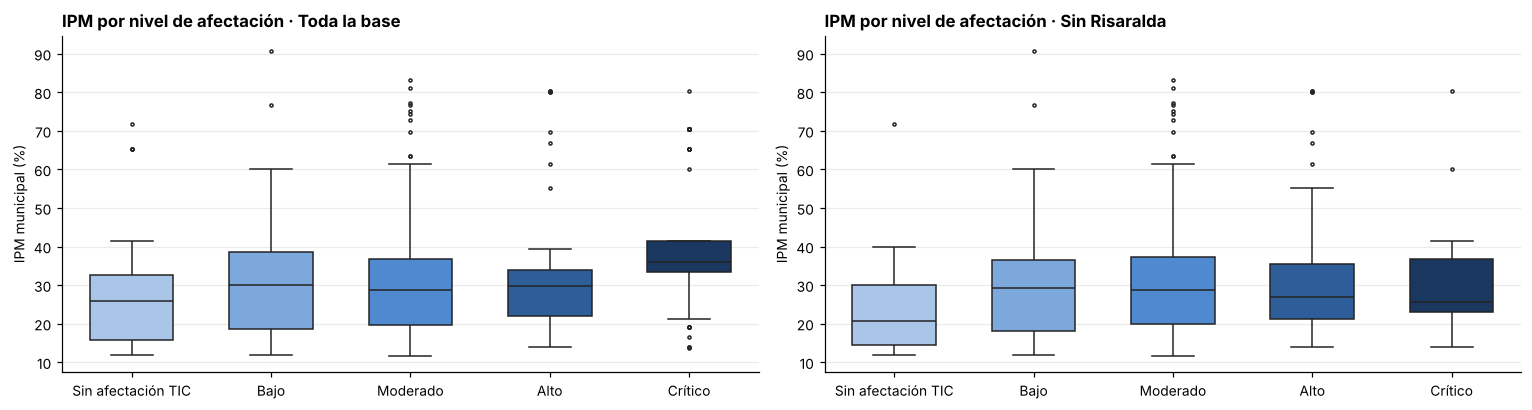

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, (base, tit) in zip(axs, [(lab2, 'Toda la base'), (lab2[lab2.departamento != 'RISARALDA'], 'Sin Risaralda')]):
    sns.boxplot(data=base, x='nivel_afectacion_cat', y='ipm', order=ORD_OBJ, palette=SEQ, ax=ax, fliersize=2, width=.6)
    ax.set_xlabel(''); ax.set_ylabel('IPM municipal (%)'); ax.set_title(f'IPM por nivel de afectación · {tit}', loc='left')
plt.tight_layout(); plt.show()

**Interpretación y elección de la prueba**

* **Normalidad:** Shapiro-Wilk rechaza la normalidad del IPM en **los cinco grupos** (p < 0,05), con distribuciones asimétricas por la cola del Chocó.
* **Homocedasticidad:** la prueba de Levene centrada en la mediana **no rechaza** la igualdad de varianzas (p = 0,7646 con toda la base; p = 0,4269
  sin Risaralda). La de Bartlett, que es sensible a la falta de normalidad, sí la rechaza sin Risaralda (p = 0,0114), por lo que se privilegia Levene.
  **Conclusión: se cumple la homocedasticidad, pero se viola la normalidad.**
* **Toda la base:** ANOVA (p < 0,0001) y Kruskal-Wallis (p < 0,0001) rechazan la igualdad entre grupos: el IPM es mayor en la clase *Crítico*. El efecto
  es pequeño-moderado (η² = 0,0675; ε² = 0,1271) y lo produce el bloque de Risaralda (colegios de municipios de pobreza media que se declararon *Crítico*).
* **Sin Risaralda:** **ni ANOVA (p = 0,0708) ni Kruskal-Wallis (p = 0,0733) son significativos** al 5 % y el efecto es casi nulo (η² = 0,0362;
  ε² = 0,0195). Alexander-Govern sí da significativo (p = 0,0065), pero esa prueba también supone normalidad dentro de cada grupo, que no se cumple.
  Esto confirma lo encontrado en el Lab 1: la pobreza del municipio **no explica la afectación declarada**; explica la fragilidad de la infraestructura.
* **Prueba más adecuada: Kruskal-Wallis.** Aunque las varianzas son homogéneas, la normalidad se viola en todos los grupos y hay atípicos (Chocó), y
  Kruskal-Wallis no depende de esos supuestos. En este caso ANOVA y Kruskal-Wallis llegan a la misma conclusión en ambas bases, lo que le da solidez.

## L2-7. Síntesis analítica y selección de variables

In [17]:
# Ranking de asociación con la variable objetivo (variables cualitativas: V de Cramér; cuantitativas: Kruskal-Wallis ε²)
rank_cual = assoc[['variable', 'V_de_Cramer']].rename(columns={'V_de_Cramer': 'Fuerza'}).assign(Medida='V de Cramér')
filas = []
for v in ['ipm', 'n_servicios_caidos', 'n_infra_afectada', 'n_sistemas_afectados', 'indice_vulnerabilidad', 'n_areas_apoyo', 'duracion_min']:
    g = [x[v].dropna().values for _, x in lab2.groupby('nivel_afectacion_cat', observed=True)]
    H, p = stats.kruskal(*g); N = sum(map(len, g)); k = len(g)
    filas.append({'variable': v, 'Fuerza': (H - k + 1) / (N - k), 'Medida': 'ε² de Kruskal-Wallis', 'p': p})
rank_cuant = pd.DataFrame(filas)
display(rank_cual.head(8).round(4)); display(rank_cuant.sort_values('Fuerza', ascending=False).round(4))

,variable,Fuerza,Medida
0,personal_afectado,0.5822,V de Cramér
1,est_sist_info,0.5608,V de Cramér
2,riesgo_continuidad,0.5439,V de Cramér
3,sede_contingencia,0.5291,V de Cramér
4,control_cuentas,0.5124,V de Cramér
5,zonas_incomunicadas,0.5077,V de Cramér
6,est_financiero,0.4955,V de Cramér
7,tramites_impedidos,0.4831,V de Cramér


,variable,Fuerza,Medida,p
6,duracion_min,0.4937,ε² de Kruskal-Wallis,0.0000
1,n_servicios_caidos,0.3583,ε² de Kruskal-Wallis,0.0000
2,n_infra_afectada,0.2429,ε² de Kruskal-Wallis,0.0000
3,n_sistemas_afectados,0.1561,ε² de Kruskal-Wallis,0.0000
0,ipm,0.1271,ε² de Kruskal-Wallis,0.0000
5,n_areas_apoyo,0.0877,ε² de Kruskal-Wallis,0.0000
4,indice_vulnerabilidad,0.0273,ε² de Kruskal-Wallis,0.0047


### Síntesis ejecutiva

**1. ¿Qué variables muestran mayor capacidad de asociación con la variable objetivo?**
Entre las cualitativas, la **afectación del personal TIC, el estado de los sistemas de información, el riesgo para la continuidad, la necesidad de sede
de contingencia, las zonas incomunicadas y el estado de la conectividad** (V de Cramér entre 0,46 y 0,58; todas con p < 0,001). La conectividad lo
confirma con χ² e información mutua (punto 5). Entre las cuantitativas, el **número de servicios caídos** y el **número de elementos de infraestructura
afectados** son las que más separan las clases (Kruskal-Wallis). La **duración del formulario** también aparece asociada, pero es un metadato de cómo se
diligenció la encuesta, no del estado de la entidad. El **IPM** casi no se asocia con la afectación declarada (sobre todo sin Risaralda), pero sí con la
fragilidad de la infraestructura (dependencia del satélite, energía inestable), que es justamente el argumento del enfoque territorial.

**2. ¿Cómo influyeron la asimetría y los atípicos en la elección de pruebas?**
Todas las variables cuantitativas clave, excepto el índice de vulnerabilidad, son asimétricas positivas y varias son leptocúrticas. La duración tiene
atípicos extremos que **anularon la correlación de Pearson** mientras Spearman y Kendall sí detectaron la asociación; en el IPM, los municipios del
Chocó (atípicos legítimos) **inflaron Pearson** frente a Spearman. En el ANOVA del IPM se violó la normalidad en los cinco grupos (la homocedasticidad sí se cumplió según Levene). Por eso se privilegian
las **pruebas no paramétricas** (Spearman, Kendall, Kruskal-Wallis) y, para categóricas, χ² complementado con información mutua y V de Cramér.

**3. ¿Qué variables descartar o transformar para el modelado?**

| Decisión | Variables | Razón |
|---|---|---|
| **Descartar** | correo, nombre, autorización de datos, incidentes cibernéticos | Constantes o vacías |
| **Descartar como predictores** | duración del formulario, días después del sismo, número de respuestas "sin información" | Describen cómo se llenó el formulario, no el estado de la entidad (fuga de información) |
| **Transformar** | duración (si se usa en análisis de calidad) | Logaritmo o winsorización por atípicos extremos |
| **Transformar** | conteos (infraestructura, sistemas, servicios caídos, áreas de apoyo) | Truncar colas o agrupar valores altos (asimetría y curtosis altas) |
| **Transformar** | textos libres (17 preguntas abiertas) | Indicadoras de "diligenció / no diligenció" |
| **Recodificar** | categorías poco frecuentes y "No se ha podido determinar" | Agrupar categorías raras (esperados < 5) y mantener "sin información" como categoría |
| **Conservar** | IPM municipal e índice de vulnerabilidad | Aportan el criterio territorial; el IPM puede usarse en terciles por su asimetría |
| **Revisar** | bloque de 145 colegios de Risaralda | Validar con MinTIC; entrenar con y sin el bloque |

In [18]:
# Exportar insumos para la aplicación de Streamlit
lab2.drop(columns=[c for c in ['correo', 'nombre', 'autoriza_datos', 'incidentes_ciber', 'clave'] if c in lab2]).to_csv(PROC / 'base_lab2.csv', index=False, encoding='utf-8-sig')
mun.to_csv(PROC / 'municipios_lab2.csv', index=False, encoding='utf-8-sig')
print('Exportados: data/base_lab2.csv', lab2.shape, 'y data/municipios_lab2.csv', mun.shape)

Exportados: data/base_lab2.csv (408, 84) y data/municipios_lab2.csv (107, 11)
